<a href="https://colab.research.google.com/github/Ahmedayman55/-EPL-Players-Clustering/blob/main/Labs/Lab4/Lab4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment: Text Generation with RNNs

In this assignment, you will explore text generation using deep learning models, specifically Recurrent Neural Networks (RNNs). Text generation is a fascinating task where the goal is to train a model that can predict the next word in a sequence, ultimately generating coherent and contextually accurate sentences or paragraphs.

You will work with a corpus of text data provided in the tutorial (from TensorFlow), which contains a large collection of Shakespeare’s works. Your objective is to implement a text generation model using RNNs and to evaluate its performance based on various metrics.

<img src="https://drek4537l1klr.cloudfront.net/teofili2/Figures/03fig09_alt.jpg" alt="Drawing"/>

**The models include:**
- Deep RNN (LSTM)
- Deep RNN (GRU)
- Bidirectional RNN


**Evaluation:**

Evaluate the performance of the text generation model using several metrics:
- Perplexity: A measure of how well the probability distribution predicted by the model aligns with the actual distribution of words in the text.
- Generated Text Quality: Subjectively evaluate the quality of the generated text by considering grammar, coherence, and creativity. This can be done by visually inspecting the generated sequences.
- BLUE Score: Character-level BLEU: BLEU can be applied at the character level by treating each character as an n-gram. This is particularly useful when the task involves generating character sequences (like poetry, code, or fine-grained character-based generation).
For example, the sequence “hello” could be evaluated by comparing 1-grams (e.g., “h”, “e”, “l”, “l”, “o”) or higher-order n-grams (e.g., “he”, “el”, “ll”, “lo”).

**Goals:**

- Compare the performance of GRU and LSTM. Is there a significant difference in the results?
- Compare the performance of the unidirectional and bidirectional RNN models.
Which model produces better results?
- Discuss the impact of bidirectional RNNs on text generation tasks.

# Import TensorFlow and other libraries

In [1]:
import tensorflow as tf
import numpy as np
import nltk
from nltk.translate.bleu_score import sentence_bleu
import os
import time

# Dataset

The Shakespeare dataset used for text generation contains a collection of works by William Shakespeare, primarily in the form of plays and sonnets. The text is used to train language models, offering an ideal example for character-level modeling due to its rich, complex language. The dataset is often preprocessed by tokenizing it into individual characters, enabling models to learn the sequential relationships between characters for generating coherent and contextually appropriate text.

To access the dataset, you can use TensorFlow's get_file method as follow:

You can inspect the dataset on [Kaggle](https://www.kaggle.com/datasets/adarshpathak/shakespeare-text/data).

In [2]:
path_to_file = tf.keras.utils.get_file('shakespeare.txt', 'https://storage.googleapis.com/download.tensorflow.org/data/shakespeare.txt')

# Read, then decode for py2 compat.
text = open(path_to_file, 'rb').read().decode(encoding='utf-8')
# length of text is the number of characters in it
print(f'Length of text: {len(text)} characters')

1115394/1115394 ━━━━━━━━━━━━━━━━━━━━ 1s 1us/step
Length of text: 1115394 characters


In [3]:
# Take a look at the first 250 characters in text
print(text[:250])

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.



# Process the text

### Vectorize the text

Before training, you need to convert the strings to a numerical representation.

The `tf.keras.layers.StringLookup` layer can convert each character into a numeric ID. It just needs the text to be split into tokens first.

In [4]:
example_texts = ['abcdefg', 'xyz']

chars = tf.strings.unicode_split(example_texts, input_encoding='UTF-8')
chars

<tf.RaggedTensor [[b'a', b'b', b'c', b'd', b'e', b'f', b'g'], [b'x', b'y', b'z']]>


Now create the [`tf.keras.layers.StringLookup`](https://www.tensorflow.org/api_docs/python/tf/keras/layers/StringLookup) layer:

Since the goal of this assignment is to generate text, it will also be important to invert this representation and recover human-readable strings from it. For this you can use tf.keras.layers.StringLookup(..., invert=True).

Note: Here instead of passing the original vocabulary generated with sorted(set(text)) use the get_vocabulary() method of the tf.keras.layers.StringLookup layer so that the [UNK] tokens is set the same way.

In [5]:
def get_string_lookup_layers(vocab):
    """
    Creates StringLookup layers for encoding characters to IDs and decoding IDs back to characters.

    Args:
        vocab (list): List of unique characters in the dataset.

    Returns:
        ids_from_chars (tf.keras.layers.StringLookup): Converts characters to IDs.
        chars_from_ids (tf.keras.layers.StringLookup): Converts IDs back to characters.
    """
    # Characters -> IDs. mask_token=None means only [UNK] is added (at index 0)
    ids_from_chars = tf.keras.layers.StringLookup(
        vocabulary=list(vocab), mask_token=None
    )

    # IDs -> characters. The notebook says to use get_vocabulary() here
    # so the [UNK] token is placed the same way in both layers
    chars_from_ids = tf.keras.layers.StringLookup(
        vocabulary=ids_from_chars.get_vocabulary(), invert=True, mask_token=None
    )
    return ids_from_chars, chars_from_ids

In [6]:
def text_from_ids(ids, chars_from_ids):
    """
    Converts a sequence of character IDs into a human-readable string.

    Args:
        ids (tf.Tensor): Tensor of character IDs.
        chars_from_ids (tf.keras.layers.StringLookup): StringLookup layer to decode IDs.

    Returns:
        tf.Tensor: Decoded string.
    """
    return tf.strings.reduce_join(chars_from_ids(ids), axis=-1)

# Create training examples and targets

Next divide the text into example sequences. Each input sequence will contain seq_length characters from the text.

For each input sequence, the corresponding targets contain the same length of text, except shifted one character to the right.

So break the text into chunks of seq_length+1. For example, say seq_length is 4 and our text is "Hello". The input sequence would be "Hell", and the target sequence "ello".

To do this first use the tf.data.Dataset.from_tensor_slices function to convert the text vector into a stream of character indices.

For training you'll need a dataset of (input, label) pairs. Where input and label are sequences. At each time step the input is the current character and the label is the next character.

Here's a function that takes a sequence as input, duplicates, and shifts it to align the input and label for each timestep:

In [7]:
def split_input_target(sequence):
    input_text = sequence[:-1]
    target_text = sequence[1:]
    return input_text, target_text

Convert Text to Numerical Sequences

In [8]:
# Initialize mapping layers
vocab = sorted(set(text))
ids_from_chars, chars_from_ids = get_string_lookup_layers(vocab)



# Convert text to character IDs
all_ids = ids_from_chars(tf.strings.unicode_split(text, 'UTF-8'))

# Create a dataset from the character IDs
ids_dataset = tf.data.Dataset.from_tensor_slices(all_ids)

Create Sequences for Training

In [9]:
seq_length = 100  # Length of each training sequence

# Batch sequences (each sequence is seq_length + 1)
sequences = ids_dataset.batch(seq_length + 1, drop_remainder=True)

# Map dataset to input-target format
dataset = sequences.map(split_input_target)

# Print sample input-output pairs
for input_example, target_example in dataset.take(1):
    print("Input :", tf.strings.reduce_join(chars_from_ids(input_example)).numpy().decode('utf-8'))
    print("Target:", tf.strings.reduce_join(chars_from_ids(target_example)).numpy().decode('utf-8'))


Input : First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You
Target: irst Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You 


# Create RNN Models

Before training our text generation models, we need to set up key parameters and prepare the dataset. These parameters control the size of batches, buffer size for shuffling, embedding dimensions, and the number of units in the recurrent layer.

Customizing Parameters for Optimization

- Increase RNN_UNITS if the model is underfitting (not capturing enough detail).
- Decrease BATCH_SIZE if memory usage is too high (e.g., when using large RNN units).
- Adjust EMBEDDING_DIM to experiment with the quality of learned character representations.

Tip: Start with these values, then fine-tune based on model performance and available computational resources!

In [11]:
# ---------------- Hyperparameters ----------------
BATCH_SIZE = 64
BUFFER_SIZE = 10000
VOCAB_SIZE = len(ids_from_chars.get_vocabulary())   # 66 (65 chars + [UNK])
EMBEDDING_DIM = 256
RNN_UNITS = 1024

# ---------------- Train / validation split ----------------
DATASET_SIZE = sum(1 for _ in dataset)
train_size = int(0.9 * DATASET_SIZE)

# Split FIRST (deterministic), THEN shuffle only the training set
train_dataset = dataset.take(train_size)
val_dataset   = dataset.skip(train_size)        # the remaining 10%, no overlap

training_dataset = (train_dataset
                    .shuffle(BUFFER_SIZE)
                    .batch(BATCH_SIZE, drop_remainder=True)
                    .prefetch(tf.data.AUTOTUNE))

validation_dataset = (val_dataset
                      .batch(BATCH_SIZE, drop_remainder=True)
                      .prefetch(tf.data.AUTOTUNE))

print("Total sequences :", DATASET_SIZE)
print("Train sequences :", train_size)
print("Val sequences   :", DATASET_SIZE - train_size)
print("Train batches   :", len(list(training_dataset)))
print("Val batches     :", len(list(validation_dataset)))

Total sequences : 11043
Train sequences : 9938
Val sequences   : 1105
Train batches   : 155
Val batches     : 17


 NOTE: Original code used .skip(int(0.1 * DATASET_SIZE)), which made the validation set overlap 80% of the training set. Also, shuffling before take/skip reshuffles every epoch, mixing train and val. Fixed: split first, then shuffle only training.

# LSTM-Based Model

Long Short-Term Memory (LSTM) is a type of Recurrent Neural Network (RNN) designed to capture long-range dependencies in sequential data. Unlike traditional RNNs, which struggle with vanishing gradients, LSTMs use gates (input, forget, and output gates) to regulate the flow of information, making them highly effective for text generation tasks.

This function defines an LSTM-based neural network for text generation.

**Function Overview:**
* [`tf.keras.layers.Embedding`](https://www.tensorflow.org/api_docs/python/tf/keras/layers/Embedding): This is the input layer, consisting of a trainable lookup table that maps the numbers of each character to a vector with `embedding_dim` dimensions.
* [`tf.keras.layers.LSTM`](https://www.tensorflow.org/api_docs/python/tf/keras/layers/LSTM): Our LSTM network, with size `units=rnn_units`.
* [`tf.keras.layers.Dense`](https://www.tensorflow.org/api_docs/python/tf/keras/layers/Dense): The output layer, with `vocab_size` outputs.


<img src="https://raw.githubusercontent.com/aamini/introtodeeplearning/2019/lab1/img/lstm_unrolled-01-01.png" alt="Drawing"/>

In [12]:
def build_lstm_model(vocab_size, embedding_dim, rnn_units, batch_size, num_layers=1):
    """
    Builds an LSTM-based text generation model.

    Parameters:
    - vocab_size (int): Number of unique characters in the vocabulary.
    - embedding_dim (int): Dimension of the word/character embeddings.
    - rnn_units (int): Number of units in the LSTM layer.
    - batch_size (int): Number of sequences processed in parallel.
    - num_layers (int): Number of stacked LSTM layers (for the experiments).

    Returns:
    - tf.keras.Model: LSTM model (compiled later in compile_and_train).
    """
    model = tf.keras.Sequential(name=f"LSTM_{num_layers}layers_{rnn_units}units")

    # Batch size is left flexible (None) so the same model can train with
    # batches of 64 and later generate text with a batch of 1.
    model.add(tf.keras.Input(shape=(None,), dtype=tf.int32))

    # 1) Embedding: character ID -> vector of size embedding_dim
    model.add(tf.keras.layers.Embedding(vocab_size, embedding_dim))

    # 2) One or more stacked LSTM layers
    for _ in range(num_layers):
        model.add(tf.keras.layers.LSTM(rnn_units, return_sequences=True))

    # 3) Output: one score (logit) per character in the vocabulary
    model.add(tf.keras.layers.Dense(vocab_size))

    return model

In [13]:
test_model = build_lstm_model(VOCAB_SIZE, EMBEDDING_DIM, RNN_UNITS, BATCH_SIZE)

# Try one batch to check the output shape
for input_batch, target_batch in training_dataset.take(1):
    predictions = test_model(input_batch)
    print("Output shape:", predictions.shape)

test_model.summary()

Output shape: (64, 100, 66)


Model: "LSTM_1layers_1024units"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, None, 256)      │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, None, 1024)     │     5,246,976 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, None, 66)       │        67,650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,331,522 (20.34 MB)

 Trainable params: 5,331,522 (20.34 MB)

 Non-trainable params: 0 (0.00 B)

**Customization & Optimization**

These experiments are required to improve model performance. You must conduct the following experiments and document your findings:

- Increase RNN_UNITS : This enhances the model’s ability to recognize deeper patterns but may increase training time.
- Experiment with EMBEDDING_DIM : Adjusting this can improve the quality of character representation.
- Stack multiple LSTM layers : This can help the model understand text more effectively.

**Submission Requirements**

- Perform at least three trials varying the parameters above.
- Keep the most performing plots and outputs in your Jupyter Notebook.


# GRU-Based Model

What is GRU?

Gated Recurrent Units (GRU) are a simplified version of LSTMs that combine the forget and input gates into a single update gate. This makes GRUs:

- Faster and more efficient than LSTMs
- Perform well on shorter sequences
- Require fewer computational resources

**Model Comparison (LSTM vs. GRU)**

To evaluate the differences between LSTM and GRU models, compare them using:

- Model Size & Number of Parameters : Use model.summary() to check the number of trainable parameters in each model.
- Training Speed & Efficiency : Measure training time per epoch for both models.

In [14]:
def build_gru_model(vocab_size, embedding_dim, rnn_units, batch_size, num_layers=1):
    """
    Builds a GRU-based text generation model.

    Parameters:
    - vocab_size (int): Number of unique characters in the vocabulary.
    - embedding_dim (int): Dimension of the word/character embeddings.
    - rnn_units (int): Number of units in the GRU layer.
    - batch_size (int): Number of sequences processed in parallel.
    - num_layers (int): Number of stacked GRU layers.

    Returns:
    - tf.keras.Model: GRU model (compiled later in compile_and_train).
    """
    model = tf.keras.Sequential(name=f"GRU_{num_layers}layers_{rnn_units}units")
    model.add(tf.keras.Input(shape=(None,), dtype=tf.int32))
    model.add(tf.keras.layers.Embedding(vocab_size, embedding_dim))

    for _ in range(num_layers):
        model.add(tf.keras.layers.GRU(rnn_units, return_sequences=True))

    model.add(tf.keras.layers.Dense(vocab_size))
    return model

In [15]:
test_gru = build_gru_model(VOCAB_SIZE, EMBEDDING_DIM, RNN_UNITS, BATCH_SIZE)

for input_batch, target_batch in training_dataset.take(1):
    print("Output shape:", test_gru(input_batch).shape)

test_gru.summary()

Output shape: (64, 100, 66)


Model: "GRU_1layers_1024units"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, None, 256)      │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, None, 1024)     │     3,938,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, None, 66)       │        67,650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,022,850 (15.35 MB)

 Trainable params: 4,022,850 (15.35 MB)

 Non-trainable params: 0 (0.00 B)

# Bidirectional Model


<img src="https://www.researchgate.net/publication/342646275/figure/fig4/AS:962238546464790@1606426955772/Comparison-between-LSTM-and-Bi-LSTM-networks-recreated-after-33.png" alt="Drawing"/>


**What is Bidirectional RNN?**

A Bidirectional Recurrent Neural Network (BiRNN) is an extension of a standard RNN that processes input sequences in both forward and backward directions. This means that at each time step, the model considers both past (left-to-right) and future (right-to-left) context, leading to better performance in many sequence-related tasks, including text generation.

**Why Use Bidirectional RNNs?**

Bidirectional RNNs are used because they capture dependencies in the input data from both directions, which is crucial for understanding context. This makes them particularly useful in tasks like language processing, where the meaning of a word can depend on both the words that come before and after it.

For example, in the sentence "The cat sat on the mat," the word "mat" is influenced by both the preceding words ("The cat sat on the") and what could potentially follow (e.g., "and looked at the mouse").

Example

Let's consider a sentence: "He opened the door."

Simple RNN: It processes the sentence from left to right, word by word:

He → opened → the → door
Each word is processed based on the previous word.

Bidirectional RNN: It processes the sentence in both directions:

Forward pass: He → opened → the → door

Backward pass: door → the → opened → He

The output at each time step is a combination of the information from both the forward and backward passes, allowing the network to understand the context better. For instance, knowing that "door" follows "the" helps confirm that "opened" likely refers to a physical action, not a metaphorical one.

**Choosing the Base RNN for Bidirectional Processing:**

One key flexibility of Bidirectional RNNs is that you can choose any recurrent architecture (LSTM, GRU, Simple RNN) as the base model.

- Bidirectional LSTM: Best for handling long-range dependencies.
- Bidirectional GRU: More computationally efficient than LSTM.
- Bidirectional Simple RNN: Less commonly used due to vanishing gradient issues.

Note: To determine the best base model for the Bidirectional RNN, you must evaluate the results from your previous experiments with different architectures (eg. LSTM and GRU).

Review previous results from training LSTM and GRU models.
Compare their performance in terms of:

- Training time per epoch
- Model size (number of parameters)
- Loss and accuracy on validation data
- Quality of generated text

Based on your findings, select the best-performing model as the base architecture for the Bidirectional RNN.


In [16]:
def build_birnn_model(vocab_size, embedding_dim, rnn_units, batch_size, rnn_type="LSTM", num_layers=1):
    """
    Builds a Bidirectional RNN-based text generation model.

    Parameters:
    - vocab_size (int): Number of unique characters in the vocabulary.
    - embedding_dim (int): Dimension of the word/character embeddings.
    - rnn_units (int): Number of units in the RNN layer.
    - batch_size (int): Number of sequences processed in parallel.
    - rnn_type (str): Type of RNN to use as the base (options: "LSTM", "GRU").
    - num_layers (int): Number of stacked bidirectional layers.

    Returns:
    - tf.keras.Model: Bidirectional RNN model (compiled later in compile_and_train).
    """
    if rnn_type == "LSTM":
        rnn_layer = tf.keras.layers.LSTM
    elif rnn_type == "GRU":
        rnn_layer = tf.keras.layers.GRU
    else:
        raise ValueError("rnn_type must be 'LSTM' or 'GRU'")

    model = tf.keras.Sequential(name=f"Bi{rnn_type}_{num_layers}layers_{rnn_units}units")
    model.add(tf.keras.Input(shape=(None,), dtype=tf.int32))
    model.add(tf.keras.layers.Embedding(vocab_size, embedding_dim))

    for _ in range(num_layers):
        # Bidirectional runs one RNN left->right and one right->left,
        # then concatenates their outputs (so output size = 2 * rnn_units)
        model.add(tf.keras.layers.Bidirectional(
            rnn_layer(rnn_units, return_sequences=True)
        ))

    model.add(tf.keras.layers.Dense(vocab_size))
    return model

In [17]:
test_bi = build_birnn_model(VOCAB_SIZE, EMBEDDING_DIM, RNN_UNITS, BATCH_SIZE, rnn_type="LSTM")

for input_batch, target_batch in training_dataset.take(1):
    print("Output shape:", test_bi(input_batch).shape)

test_bi.summary()

Output shape: (64, 100, 66)


Model: "BiLSTM_1layers_1024units"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, None, 256)      │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, None, 2048)     │    10,493,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, None, 66)       │       135,234 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,646,082 (40.61 MB)

 Trainable params: 10,646,082 (40.61 MB)

 Non-trainable params: 0 (0.00 B)

# Evaluating the Models

Model Selection

In [27]:
# Choose model type
model_type = "LSTM"  # Change to "GRU" or "BiLSTM"

if model_type == "LSTM":
    model = build_lstm_model(VOCAB_SIZE, EMBEDDING_DIM, RNN_UNITS, BATCH_SIZE)
elif model_type == "GRU":
    model = build_gru_model(VOCAB_SIZE, EMBEDDING_DIM, RNN_UNITS, BATCH_SIZE)
elif model_type == "BiLSTM":
    model = build_birnn_model(VOCAB_SIZE, EMBEDDING_DIM, RNN_UNITS, BATCH_SIZE)

print(f"Using {model_type} model for training.")

Using LSTM model for training.


Compile & Train the Model

In [28]:
def compile_and_train(model, path, EPOCHS = 30):
  # Define loss function
  def loss(labels, logits):
    return tf.keras.losses.sparse_categorical_crossentropy(labels, logits, from_logits=True)

  # Compile the model
  model.compile(optimizer='adam', loss=loss, metrics=['accuracy'])
  # Ensure checkpoint directory exists
  checkpoint_dir = f'./{path}'
  os.makedirs(checkpoint_dir, exist_ok=True)

  checkpoint_prefix = os.path.join(checkpoint_dir, "ckpt_{epoch}")

  checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath=checkpoint_prefix + '.weights.h5',
    save_weights_only=True
  )

  # Train the model
  history = model.fit(
    training_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS,
    callbacks=[checkpoint_callback]
)

  return history

### Trial 1: LSTM (1 layer, 1024 units, embedding 256)

In [29]:
EPOCHS = 20

start = time.time()
history_lstm = compile_and_train(model, "checkpoints_lstm", EPOCHS)
lstm_time_per_epoch = (time.time() - start) / EPOCHS

lstm_model = model   # keep a reference, because `model` will be reused for GRU
print(f"\nLSTM - average time per epoch: {lstm_time_per_epoch:.1f} s")

Epoch 1/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 19s 107ms/step - accuracy: 0.2667 - loss: 2.7309 - val_accuracy: 0.3481 - val_loss: 2.2448
Epoch 2/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 18s 100ms/step - accuracy: 0.3992 - loss: 2.0604 - val_accuracy: 0.4149 - val_loss: 1.9640
Epoch 3/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 16s 95ms/step - accuracy: 0.4696 - loss: 1.7986 - val_accuracy: 0.4593 - val_loss: 1.8177
Epoch 4/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 19s 114ms/step - accuracy: 0.5096 - loss: 1.6435 - val_accuracy: 0.4848 - val_loss: 1.7333
Epoch 5/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 17s 95ms/step - accuracy: 0.5357 - loss: 1.5453 - val_accuracy: 0.5032 - val_loss: 1.6622
Epoch 6/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 17s 101ms/step - accuracy: 0.5533 - loss: 1.4778 - val_accuracy: 0.5183 - val_loss: 1.6214
Epoch 7/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 18s 107ms/step - accuracy: 0.5663 - loss: 1.4267 - val_accuracy: 0.5282 - val_loss: 1.5850
Epoch 8/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 16s 95ms/step - accuracy: 0.5766 - loss: 1.38

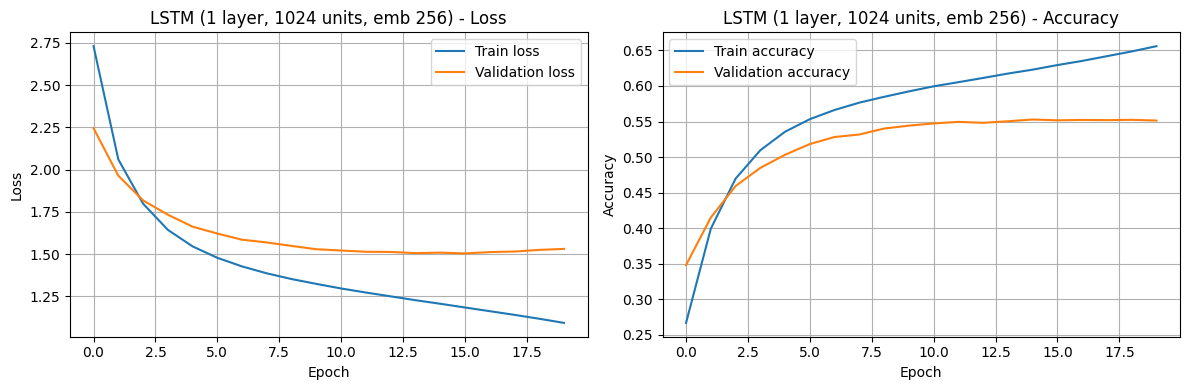

Best val_loss = 1.5038 at epoch 16
Best val_accuracy = 0.5528


In [30]:
import matplotlib.pyplot as plt

def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # Loss
    axes[0].plot(history.history['loss'], label='Train loss')
    axes[0].plot(history.history['val_loss'], label='Validation loss')
    axes[0].set_title(f'{title} - Loss')
    axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
    axes[0].legend(); axes[0].grid(True)

    # Accuracy
    axes[1].plot(history.history['accuracy'], label='Train accuracy')
    axes[1].plot(history.history['val_accuracy'], label='Validation accuracy')
    axes[1].set_title(f'{title} - Accuracy')
    axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy')
    axes[1].legend(); axes[1].grid(True)

    plt.tight_layout()
    plt.show()

    best_epoch = int(np.argmin(history.history['val_loss'])) + 1
    print(f"Best val_loss = {min(history.history['val_loss']):.4f} at epoch {best_epoch}")
    print(f"Best val_accuracy = {max(history.history['val_accuracy']):.4f}")

plot_history(history_lstm, "LSTM (1 layer, 1024 units, emb 256)")

# Generate Text Using the Model

In [20]:
class OneStepTextGenerator(tf.keras.Model):
    def __init__(self, model, chars_from_ids, ids_from_chars, temperature=1.0, context_length=100):
        """
        Initializes the OneStepTextGenerator.

        Parameters:
        - model: Trained text generation model (e.g., LSTM or GRU).
        - chars_from_ids: Function mapping character IDs to characters.
        - ids_from_chars: Function mapping characters to their respective IDs.
        - temperature (float): Controls randomness in text generation.
          -> Higher temperature (> 1.0): Produces more diverse and unpredictable text.
          -> Lower temperature (< 1.0): Makes the model more confident but results in repetitive text.
          -> Temperature = 1.0: Standard behavior without biasing randomness.
        - context_length (int): How many previous characters the model sees at each step
          (same as seq_length used in training).
        """
        super().__init__()
        self.model = model
        self.chars_from_ids = chars_from_ids
        self.ids_from_chars = ids_from_chars
        self.temperature = temperature
        self.context_length = context_length

    def generate_text(self, start_string, num_generate=1000):
        """
        Generates text one character at a time based on a starting string.

        Parameters:
        - start_string (str): Initial text prompt.
        - num_generate (int): Number of characters to generate.

        Returns:
        - str: Generated text.
        """
        # Convert start string to a list of IDs
        input_ids = list(self.ids_from_chars(
            tf.strings.unicode_split(start_string, 'UTF-8')).numpy())
        text_generated = []

        for _ in range(num_generate):
            # Feed the last `context_length` characters so the model has context
            context = input_ids[-self.context_length:]
            input_eval = tf.constant([context], dtype=tf.int32)

            # Get predictions for the last position
            predictions = self.model(input_eval, training=False)
            logits = predictions[:, -1, :].numpy() / self.temperature

            # Never generate the [UNK] token (ID 0)
            logits[:, 0] = -1e9

            # Sample the next character ID from the probability distribution
            predicted_id = int(tf.random.categorical(logits, num_samples=1)[0, 0])

            # Add it to the context and to the output
            input_ids.append(predicted_id)
            text_generated.append(self.chars_from_ids(predicted_id).numpy().decode('utf-8'))

        return start_string + ''.join(text_generated)

### Fix for the text generator

In the original code, the model only got the **last generated character** as input at each step, and the hidden state wasn't passed either. So the model basically had no memory of what it wrote before, and the output would be random even after training.

I changed it so the model gets the **last 100 characters** at each step (same as `seq_length`). This way it always has context, and it works for LSTM, GRU and the bidirectional model. I also blocked the `[UNK]` token so it doesn't appear in the generated text.

In [22]:
print(tf.config.list_physical_devices('GPU'))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# Evaluate Model Performance

**1- Perplexity (PP)**

TODO: Measures uncertainty in predicting next character for each model and leave the results in the Notebook.

***Lower values = better model***

In [36]:
def perplexity(logits, labels):
    loss = tf.keras.losses.sparse_categorical_crossentropy(labels, logits, from_logits=True)
    return np.exp(np.mean(loss))

def evaluate_model_perplexity(model, dataset):
    total_loss = 0.0
    total_tokens = 0

    for input_batch, label_batch in dataset:
        logits = model(input_batch, training=False)
        n_tokens = tf.size(label_batch).numpy()
        # log(perplexity) = average loss of the batch -> multiply by number of tokens
        total_loss += np.log(perplexity(logits, label_batch)) * n_tokens
        total_tokens += n_tokens

    avg_loss = total_loss / total_tokens
    return np.exp(avg_loss)

**Fix:** the original function added the average loss of each batch but divided by the total number of tokens, so the perplexity always came out ≈ 1. I multiplied each batch loss by the number of tokens in the batch so the average is correct.

In [46]:
import pandas as pd
results_df = pd.DataFrame(results).T
results_df[["params", "time/epoch (s)", "val_loss", "perplexity"]].sort_values("perplexity")

,params,time/epoch (s),val_loss,perplexity
BiLSTM,10646082.0,31.3,0.0221,1.022
LSTM_2layers,13724226.0,37.1,1.4846,4.413
LSTM_emb512,6396994.0,19.6,1.4889,4.432
LSTM_units2048,19034690.0,51.1,1.4951,4.460
LSTM,5331522.0,17.2,1.5038,4.499
GRU,4022850.0,14.4,1.5221,4.582


**2- Text Coherence & Fluency**

Subjective evaluation by examining generated text

**TODO: Generate at least 3 Samples (one from each model) and leave them in the Notebook.**

In [47]:
tf.random.set_seed(42)   # same randomness for all models -> fair comparison

for name, m in [("LSTM", lstm_model), ("GRU", gru_model), ("BiLSTM", bilstm_model)]:
    generator = OneStepTextGenerator(m, chars_from_ids, ids_from_chars, temperature=1.0)
    print(f"==================== {name} ====================")
    print(generator.generate_text("ROMEO:", num_generate=400))
    print()

==================== LSTM ====================
ROMEO:
No, no; but stay to jest into your way.

KING RICHARD II:
Ay, in mad!
I have not done bound as this in joy?

LEONTES:
Sweet spirit, that he done so much.

DUKE
Every Perbute,
And this I cannot confes to be, take on
Throw from my mistress of us was the world!
And where you do mean a gooder in the near.

GEORGE:
No father Edward late of Clear's speed!
O, he did serve I never so bad,
To beauty medit

==================== GRU ====================
ROMEO:
I know the main of when I perceive
of country ever lent us as alghour'd my coat,
Hortensio, pay me; look'd again forbear;
For some ill a ship by dangerous,
Would with whom he and the sun duty of him,
Stay to the king, I holping shall.

KING EDWARD IV:
Now, after you to the liant.

CORIOLANUS:
Prove, young Richard,
Becomes me, as you have done thee now;
But say thou not may be vict your subject,
D

==================== BiLSTM ====================
ROMEO:
Mare, here your had my ho ma dis th

**3- BLEU Score**

TODO: Measures similarity between generated and real text for each model and leave the results in the Notebook.

In [32]:
def compute_bleu(reference, generated):
    return sentence_bleu([list(reference)], list(generated))

def evaluate_model_bleu(model, dataset):
    bleu_scores = []

    for input_batch, label_batch in dataset:
        logits = model(input_batch, training=False)
        predictions = tf.argmax(logits, axis=-1)

        label_batch = label_batch.numpy()

        for pred_seq, true_seq in zip(predictions, label_batch):
            # Decode sequences to text
            pred_text = text_from_ids(pred_seq, chars_from_ids).numpy().decode('utf-8')
            true_text = text_from_ids(true_seq, chars_from_ids).numpy().decode('utf-8')

            # Compute BLEU score for each sample
            bleu = compute_bleu(true_text, pred_text)
            bleu_scores.append(bleu)

    return np.mean(bleu_scores)

In [37]:
results = {}   # we'll store every model's results here for the final comparison

def evaluate_and_store(name, model, history, ckpt_dir, time_per_epoch):
    # Load the best epoch's weights
    best_epoch = int(np.argmin(history.history['val_loss'])) + 1
    model.load_weights(f"./{ckpt_dir}/ckpt_{best_epoch}.weights.h5")
    print(f"{name}: loaded best weights from epoch {best_epoch}")

    pp = evaluate_model_perplexity(model, validation_dataset)
    bleu = evaluate_model_bleu(model, validation_dataset)

    results[name] = {
        "params": model.count_params(),
        "time/epoch (s)": round(time_per_epoch, 1),
        "best epoch": best_epoch,
        "val_loss": round(min(history.history['val_loss']), 4),
        "val_acc": round(history.history['val_accuracy'][best_epoch - 1], 4),
        "perplexity": round(float(pp), 3),
        "BLEU": round(float(bleu), 4),
    }
    print(results[name])

evaluate_and_store("LSTM", lstm_model, history_lstm, "checkpoints_lstm", lstm_time_per_epoch)

LSTM: loaded best weights from epoch 16
{'params': 5331522, 'time/epoch (s)': 17.2, 'best epoch': 16, 'val_loss': 1.5038, 'val_acc': 0.5517, 'perplexity': 4.499, 'BLEU': 0.2895}


In [38]:
gen_lstm = OneStepTextGenerator(lstm_model, chars_from_ids, ids_from_chars, temperature=1.0)
lstm_sample = gen_lstm.generate_text("ROMEO:", num_generate=500)
print(lstm_sample)

ROMEO:
And often great redimity, it means.

DUKE VINCENTIO:
Hold on form for many thing to scratch? one friend,
And they are gone to pardon me.
I not frail your bones should the prince to-morrop!
Ah, sir.

MARIANA:
Double in faint; for thou art mouth tape?

JULIET:
Nor Jodio, mighty!

GLOUCESTER:
You needs not the late goff sorrow together.

LADY CAPULET:
I am, dost thou intentainge thy bond,
And then say'st thou read'st the best more extent;
And hath made thee to breathe our richs, conceived
That bef


In [39]:
def run_trial(name, build_fn, embedding_dim, rnn_units, num_layers=1, epochs=20, **kwargs):
    """Builds a FRESH model, trains it, plots it, evaluates it and prints a sample."""
    model = build_fn(VOCAB_SIZE, embedding_dim, rnn_units, BATCH_SIZE,
                     num_layers=num_layers, **kwargs)
    ckpt_dir = f"checkpoints_{name}"

    start = time.time()
    history = compile_and_train(model, ckpt_dir, epochs)
    time_per_epoch = (time.time() - start) / epochs

    plot_history(history, name)
    evaluate_and_store(name, model, history, ckpt_dir, time_per_epoch)

    sample = OneStepTextGenerator(model, chars_from_ids, ids_from_chars).generate_text("ROMEO:", 300)
    print("\n--- Sample ---\n" + sample)
    return model, history

 ### Trial 2: LSTM with 2048 units

Epoch 1/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 55s 334ms/step - accuracy: 0.2910 - loss: 2.6147 - val_accuracy: 0.3845 - val_loss: 2.1015
Epoch 2/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 50s 310ms/step - accuracy: 0.4500 - loss: 1.8643 - val_accuracy: 0.4603 - val_loss: 1.8163
Epoch 3/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 50s 311ms/step - accuracy: 0.5222 - loss: 1.5942 - val_accuracy: 0.5076 - val_loss: 1.6659
Epoch 4/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 51s 317ms/step - accuracy: 0.5601 - loss: 1.4494 - val_accuracy: 0.5327 - val_loss: 1.5748
Epoch 5/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 50s 310ms/step - accuracy: 0.5824 - loss: 1.3600 - val_accuracy: 0.5417 - val_loss: 1.5350
Epoch 6/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 51s 318ms/step - accuracy: 0.6001 - loss: 1.2906 - val_accuracy: 0.5518 - val_loss: 1.5026
Epoch 7/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 51s 317ms/step - accuracy: 0.6162 - loss: 1.2297 - val_accuracy: 0.5556 - val_loss: 1.4951
Epoch 8/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 51s 320ms/step - accuracy: 0.6322 - loss: 1

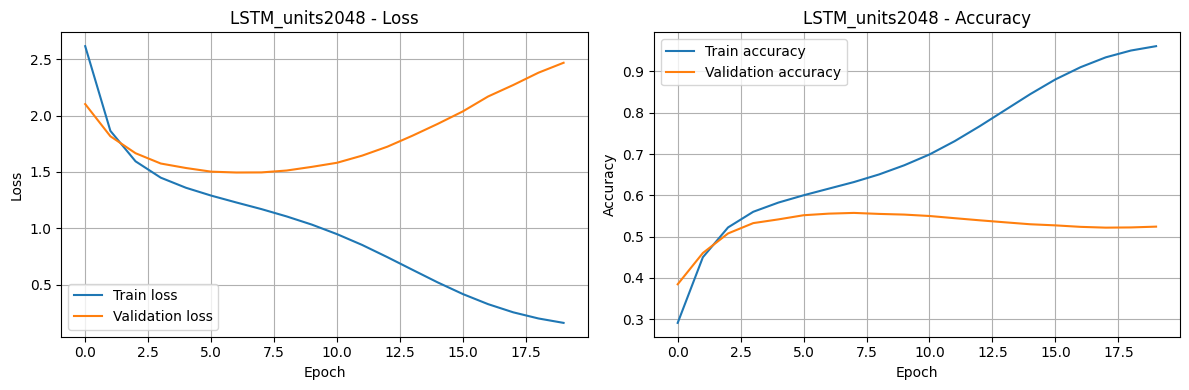

Best val_loss = 1.4951 at epoch 7
Best val_accuracy = 0.5574
LSTM_units2048: loaded best weights from epoch 7
{'params': 19034690, 'time/epoch (s)': 51.1, 'best epoch': 7, 'val_loss': 1.4951, 'val_acc': 0.5556, 'perplexity': 4.46, 'BLEU': 0.2908}

--- Sample ---
ROMEO:
Go, take, four manamorr; no man not have not on him:
As what service, what?

BISHOP OF CARLISLE:
The father monume that made thee factaary?
3OREEBES:
And first help men: yea, himself;
Or that I would bear her king, even in the mind
For my that fielded this happy lady to.
But spit them such a garlen


In [40]:
lstm_2048, hist_lstm_2048 = run_trial("LSTM_units2048", build_lstm_model,
                                      embedding_dim=256, rnn_units=2048)

Increasing RNN units to 2048 gave only a tiny improvement in validation loss, but the model overfit much faster (best epoch ≈ 7 instead of 16) and each epoch took longer. More units = more capacity to memorize, not necessarily to generalize.

 ### Trial 3: LSTM with embedding dim 512

Epoch 1/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 22s 117ms/step - accuracy: 0.3442 - loss: 2.3362 - val_accuracy: 0.4210 - val_loss: 1.9525
Epoch 2/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 21s 125ms/step - accuracy: 0.4926 - loss: 1.7071 - val_accuracy: 0.4917 - val_loss: 1.7208
Epoch 3/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 19s 106ms/step - accuracy: 0.5455 - loss: 1.5070 - val_accuracy: 0.5199 - val_loss: 1.6107
Epoch 4/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 19s 113ms/step - accuracy: 0.5711 - loss: 1.4054 - val_accuracy: 0.5364 - val_loss: 1.5473
Epoch 5/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 19s 113ms/step - accuracy: 0.5877 - loss: 1.3392 - val_accuracy: 0.5458 - val_loss: 1.5158
Epoch 6/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 20s 118ms/step - accuracy: 0.6007 - loss: 1.2882 - val_accuracy: 0.5518 - val_loss: 1.5019
Epoch 7/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 19s 110ms/step - accuracy: 0.6123 - loss: 1.2454 - val_accuracy: 0.5543 - val_loss: 1.4889
Epoch 8/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 19s 114ms/step - accuracy: 0.6231 - loss: 1

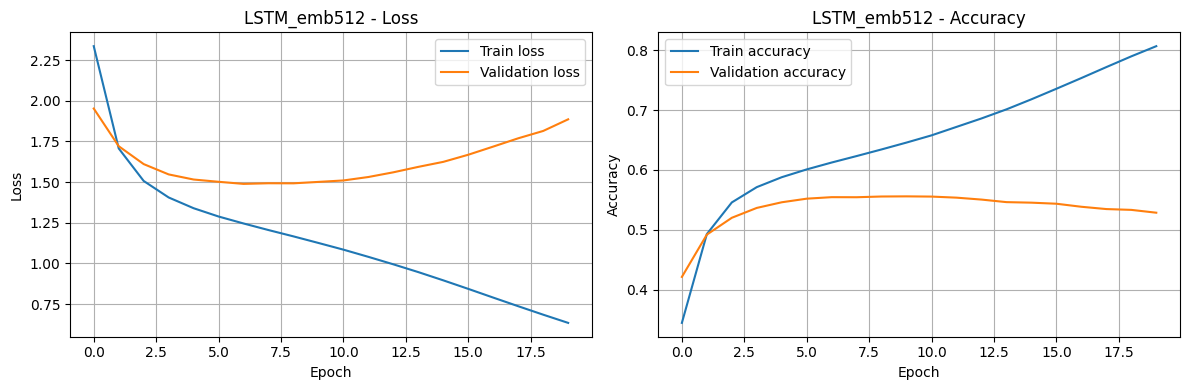

Best val_loss = 1.4889 at epoch 7
Best val_accuracy = 0.5557
LSTM_emb512: loaded best weights from epoch 7
{'params': 6396994, 'time/epoch (s)': 19.6, 'best epoch': 7, 'val_loss': 1.4889, 'val_acc': 0.5543, 'perplexity': 4.432, 'BLEU': 0.2857}

--- Sample ---
ROMEO:
That any in the motter of the break--

SICINIUS:
Crumle! O the poor father's an apen.
Thou hiss oft better, you are not valiant'st this
weep and man hath discredected like all of women.

JULIET:
O, when Warwicks Lady alray.

SLY:
Yet where it were pretty tongue?

Servant:

amend that, sir. Your bea


In [41]:
lstm_emb512, hist_lstm_emb512 = run_trial("LSTM_emb512", build_lstm_model,
                                          embedding_dim=512, rnn_units=1024)

Increasing Embedding dimensions to 512 made the model converge faster (best epoch ≈ 7–9 instead of 16) but the best validation loss was almost the same as the baseline. The embedding only adds a few parameters (66 × 512), so it isn’t the main factor in performance.

 ### Trial 4: 2 stacked LSTM layers

Epoch 1/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 41s 241ms/step - accuracy: 0.2523 - loss: 2.7799 - val_accuracy: 0.3624 - val_loss: 2.1852
Epoch 2/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 36s 220ms/step - accuracy: 0.4385 - loss: 1.9159 - val_accuracy: 0.4558 - val_loss: 1.8442
Epoch 3/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 38s 233ms/step - accuracy: 0.5200 - loss: 1.6126 - val_accuracy: 0.5022 - val_loss: 1.6716
Epoch 4/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 36s 224ms/step - accuracy: 0.5568 - loss: 1.4639 - val_accuracy: 0.5287 - val_loss: 1.5808
Epoch 5/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 37s 222ms/step - accuracy: 0.5789 - loss: 1.3747 - val_accuracy: 0.5400 - val_loss: 1.5373
Epoch 6/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 37s 226ms/step - accuracy: 0.5953 - loss: 1.3096 - val_accuracy: 0.5484 - val_loss: 1.5051
Epoch 7/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 36s 222ms/step - accuracy: 0.6097 - loss: 1.2544 - val_accuracy: 0.5552 - val_loss: 1.4884
Epoch 8/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 36s 224ms/step - accuracy: 0.6240 - loss: 1

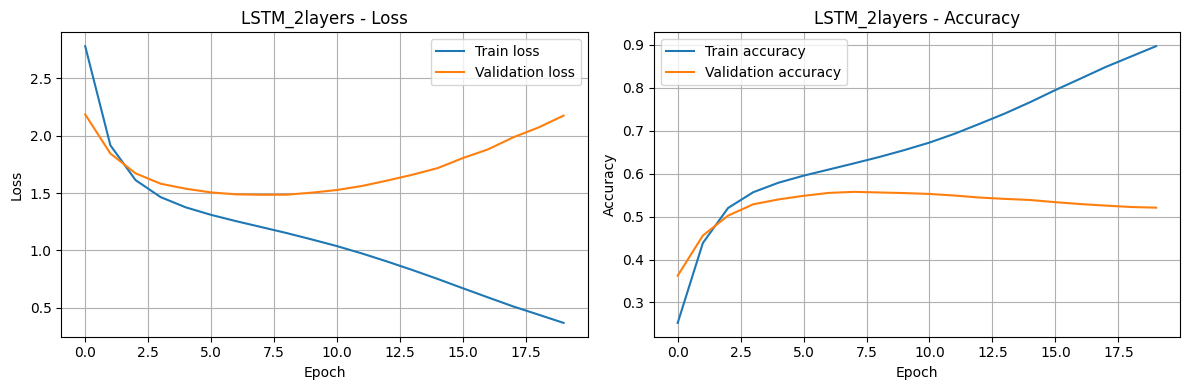

Best val_loss = 1.4846 at epoch 8
Best val_accuracy = 0.5576
LSTM_2layers: loaded best weights from epoch 8
{'params': 13724226, 'time/epoch (s)': 37.1, 'best epoch': 8, 'val_loss': 1.4846, 'val_acc': 0.5576, 'perplexity': 4.413, 'BLEU': 0.291}

--- Sample ---
ROMEO:
Friend: stay, my lord citchs and false this friends;
Even so such discinion the secret of my sword,
The king's time descent, with sheddes do it means
The fielded of with a side to grew a life.
O LangaBous horten, we may I sey
The greatest tale to you his absent Gentleman!

SICINIUS:

GeMan:
Worthy,


In [42]:
lstm_2layers, hist_lstm_2layers = run_trial("LSTM_2layers", build_lstm_model,
                                            embedding_dim=256, rnn_units=1024, num_layers=2)

Stacking 2 LSTM layers gave a similar best validation loss to the other trials, but nearly doubled the parameters and training time. It also overfit faster than the baseline. With only ~1MB of text, the dataset is too small for a deeper model to show a clear benefit.

In [43]:
import pandas as pd
pd.DataFrame(results).T

,params,time/epoch (s),best epoch,val_loss,val_acc,perplexity,BLEU
LSTM,5331522.0,17.2,16.0,1.5038,0.5517,4.499,0.2895
LSTM_units2048,19034690.0,51.1,7.0,1.4951,0.5556,4.460,0.2908
LSTM_emb512,6396994.0,19.6,7.0,1.4889,0.5543,4.432,0.2857
LSTM_2layers,13724226.0,37.1,8.0,1.4846,0.5576,4.413,0.2910


### LSTM Experiments – Summary

- **2048 units:** slightly better than the baseline but the model is 3.6x bigger and 3x slower. It also overfit very fast (best epoch 7). Not worth it.
- **Embedding 512:** almost the same perplexity as the 2-layer model, with only a small increase in parameters and training time. Best trade-off.
- **2 stacked layers:** best results overall (lowest perplexity 4.41, highest accuracy and BLEU), but 2x slower than the baseline.

Overall, all the improvements were small (< 2% in perplexity). Bigger models learned faster but also started overfitting earlier, so I think the dataset size (~1M characters) is the main limit, not the model size. BLEU was almost the same for all models, so perplexity was more useful for comparing them.

Epoch 1/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 16s 84ms/step - accuracy: 0.3119 - loss: 2.5314 - val_accuracy: 0.3799 - val_loss: 2.0868
Epoch 2/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 15s 83ms/step - accuracy: 0.4493 - loss: 1.8707 - val_accuracy: 0.4518 - val_loss: 1.8443
Epoch 3/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 14s 75ms/step - accuracy: 0.5155 - loss: 1.6250 - val_accuracy: 0.4980 - val_loss: 1.6993
Epoch 4/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 15s 79ms/step - accuracy: 0.5503 - loss: 1.4916 - val_accuracy: 0.5183 - val_loss: 1.6226
Epoch 5/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 15s 81ms/step - accuracy: 0.5711 - loss: 1.4087 - val_accuracy: 0.5334 - val_loss: 1.5774
Epoch 6/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 19s 77ms/step - accuracy: 0.5855 - loss: 1.3503 - val_accuracy: 0.5409 - val_loss: 1.5521
Epoch 7/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 15s 83ms/step - accuracy: 0.5980 - loss: 1.3016 - val_accuracy: 0.5505 - val_loss: 1.5283
Epoch 8/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 14s 81ms/step - accuracy: 0.6087 - loss: 1.2586 - 

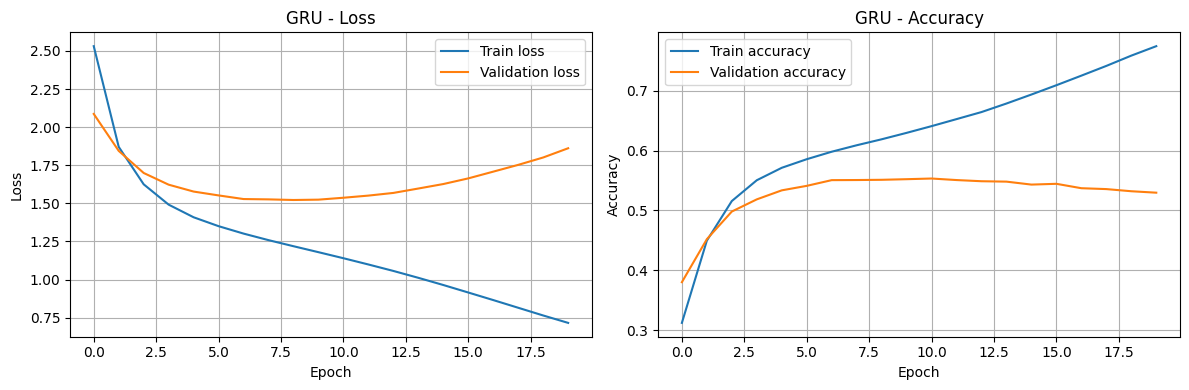

Best val_loss = 1.5221 at epoch 9
Best val_accuracy = 0.5532
GRU: loaded best weights from epoch 9


/usr/local/lib/python3.13/dist-packages/nltk/translate/bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 4-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)


{'params': 4022850, 'time/epoch (s)': 14.4, 'best epoch': 9, 'val_loss': 1.5221, 'val_acc': 0.551, 'perplexity': 4.582, 'BLEU': 0.2876}

--- Sample ---
ROMEO:
The one fides of high.

VIRGILIA:
I will to your part condition,
Ungers, having the please that blows, may desperace yer:
Every calse, do not not hell!
For which he had that sound of battle: lo,
We the vely thought of his death, not yonder
If heavy meins, the Emplewile and my company
Than dogring c


In [44]:
gru_model, history_gru = run_trial("GRU", build_gru_model,
                                   embedding_dim=256, rnn_units=1024)

### LSTM vs GRU

Both models use the same settings (embedding 256, 1024 units, 1 layer).

- **Size:** GRU has 4.02M parameters vs 5.33M for LSTM (25% fewer), because GRU has 3 gates and LSTM has 4.
- **Speed:** GRU took 14.4 s/epoch vs 17.2 s for LSTM, and reached its best val_loss at epoch 9 instead of 16.
- **Quality:** LSTM was slightly better (perplexity 4.50 vs 4.58, BLEU almost the same). The generated text from both looks similar: correct format and names, but sentences don't really make sense.

There is no significant difference in quality. GRU is more efficient, LSTM is a bit more accurate. Since LSTM gave the better results, I chose **LSTM as the base for the Bidirectional model**.

Epoch 1/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 37s 213ms/step - accuracy: 0.7361 - loss: 1.1135 - val_accuracy: 0.9901 - val_loss: 0.0477
Epoch 2/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 30s 179ms/step - accuracy: 0.9921 - loss: 0.0324 - val_accuracy: 0.9923 - val_loss: 0.0299
Epoch 3/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 32s 189ms/step - accuracy: 0.9928 - loss: 0.0267 - val_accuracy: 0.9927 - val_loss: 0.0267
Epoch 4/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 32s 192ms/step - accuracy: 0.9930 - loss: 0.0250 - val_accuracy: 0.9929 - val_loss: 0.0255
Epoch 5/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 30s 184ms/step - accuracy: 0.9932 - loss: 0.0241 - val_accuracy: 0.9930 - val_loss: 0.0248
Epoch 6/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 31s 185ms/step - accuracy: 0.9934 - loss: 0.0234 - val_accuracy: 0.9932 - val_loss: 0.0241
Epoch 7/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 31s 188ms/step - accuracy: 0.9935 - loss: 0.0227 - val_accuracy: 0.9934 - val_loss: 0.0235
Epoch 8/20
155/155 ━━━━━━━━━━━━━━━━━━━━ 31s 187ms/step - accuracy: 0.9936 - loss: 0

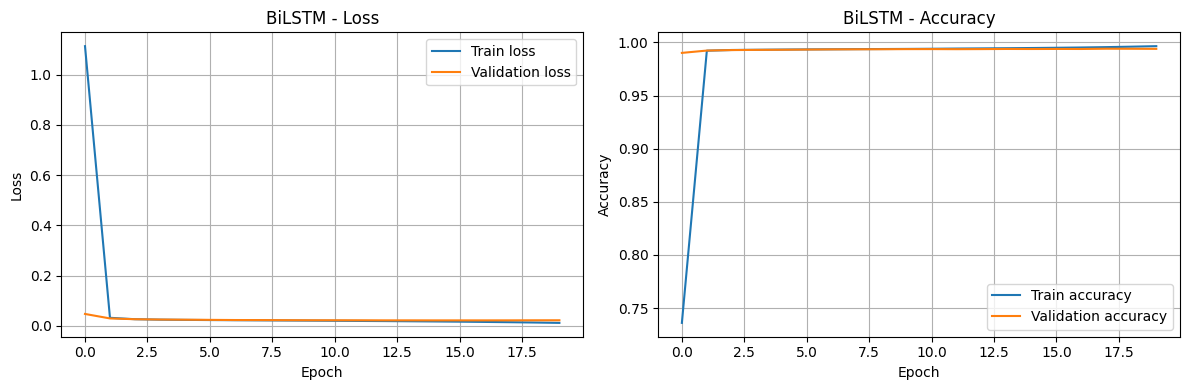

Best val_loss = 0.0221 at epoch 15
Best val_accuracy = 0.9940
BiLSTM: loaded best weights from epoch 15
{'params': 10646082, 'time/epoch (s)': 31.3, 'best epoch': 15, 'val_loss': 0.0221, 'val_acc': 0.9937, 'perplexity': 1.022, 'BLEU': 0.9936}

--- Sample ---
ROMEO:
Thous, kinco, Murouse.
That forome, 'tare ho moture the hon indet mis?

GARTI OF YLIZHARD coO:
Th laccome apreffordsty he witht the
art, tho cose thon hat magh a foale, a bes, I Go ar oune of fik I mome come!
Ses Hy lived o' gauth wnith Whouck Hearg fealleay, os feros!

EYKIO:

The sh to mard 'ling


In [45]:
bilstm_model, history_bilstm = run_trial("BiLSTM", build_birnn_model,
                                         embedding_dim=256, rnn_units=1024, rnn_type="LSTM")

# Conclusion

### 1. GRU vs LSTM
With the same settings, LSTM got a slightly better perplexity (4.50 vs 4.58) and almost the same BLEU (0.290 vs 0.288). GRU has 25% fewer parameters (4.0M vs 5.3M), is about 16% faster per epoch (14.4 s vs 17.2 s), and reached its best epoch earlier (9 vs 16). So there is **no significant difference in quality**; GRU is just more efficient. The generated text from both looks similar: correct play format and character names, mostly real words, but the sentences don't make sense.

### 2. Unidirectional vs Bidirectional
On paper the BiLSTM looks much better: 99.4% validation accuracy, perplexity 1.02 and BLEU 0.99, compared with ~55%, ~4.5 and ~0.29 for the other models. But the generated text is clearly **worse**: it keeps the format, but most words are invented ("kinco", "Murouse", "YLIZHARD").

So the **unidirectional models (LSTM/GRU) are better for text generation**, even though their scores look lower.

### 3. Impact of bidirectional RNNs on text generation
The reason is that the backward LSTM reads the sequence from right to left, so at each position it has already seen the next character, which is exactly the target. The model doesn't learn to predict; it just copies the answer from the input. That's why it reached ~99% accuracy after only 1 epoch.

During generation there is no future text (we generate one character at a time from left to right), so the backward part has nothing useful to read, and the model performs badly.

Bidirectional RNNs are useful when the whole sequence is available in advance (text classification, named-entity tagging, translation encoders), but **they are not suitable for next-character text generation**. Their perplexity and BLEU here are misleading because of this information leak.